CELL 1: CÀI ĐẶT MÔI TRƯỜNG & CÔNG CỤ XUẤT CODE CHO ESP32

In [ ]:
!pip install m2cgen

CELL 2: CHUẨN HÓA DỮ LIỆU
$$\text{Giá trị chuẩn hóa} = \frac{\text{Giá trị kênh màu } (F_i)}{\text{Giá trị kênh } CLEAR}
$$Ví dụ cụ thể trên dòng số 0:
Trước khi chia (số gốc từ cảm biến):
F1 = 687, F4 = 14159, CLEAR = 18944.
Sau khi chia cho CLEAR:F1 mới = $687 \div 18944 = \mathbf{0.036265}$   F4 mới = $14159 \div 18944 = \mathbf{0.747413}$  

In [14]:
import pandas as pd
import numpy as np

# 1. Đọc file CSV (sửa lại tên file nếu bạn đã đổi tên)
df = pd.read_csv('ĐKTĐ _ 16_11_2026 - Trang tính1.csv')

# 2. Xóa cột 'Raw data' (nếu có) và xóa dòng trùng lặp
if 'Raw data' in df.columns:
    df = df.drop(columns=['Raw data'])
df = df.drop_duplicates().reset_index(drop=True)

# 3. Chuẩn hóa 9 kênh phổ chia cho kênh CLEAR
spectral_cols = ['F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'NIR']
X = df[spectral_cols].div(df['CLEAR'], axis=0)
y = df['Label']

print(f"Số mẫu sạch sẵn sàng train: {len(df)} mẫu")
print("Phân bố nhãn:\n", y.value_counts())
X.head()

Số mẫu sạch sẵn sàng train: 151 mẫu
Phân bố nhãn:
 Label
1    80
0    71
Name: count, dtype: int64


,F1,F2,F3,F4,F5,F6,F7,F8,NIR
0,0.036265,0.376900,0.349187,0.747413,0.996569,0.629223,0.487859,0.163271,0.068623
1,0.040471,0.360504,0.326932,0.628614,1.086845,0.992603,0.794836,0.084676,0.050571
2,0.035356,0.364101,0.339794,0.728984,1.003499,0.662002,0.516987,0.130513,0.062701
3,0.037901,0.399809,0.369982,0.779491,1.018670,0.636634,0.493160,0.168872,0.066831
4,0.037360,0.426509,0.380484,0.759186,0.979292,0.588300,0.454590,0.130822,0.108517


**CELL 3: HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH**

NOTE: Tạo đặc trưng tỷ số phổ (Feature Engineering): Tính thêm 3 tỷ số quan trọng giữa dải màu Cam/Đỏ và Xanh lá/Diệp lục (R_F6_F4 = F6/F4, R_F7_F4 = F7/F4, R_F7_F8 = F7/F8). Việc lấy dải màu tăng khi chín chia cho dải màu giảm khi chín giúp tách biệt hoàn toàn cả những quả ương nằm sát ranh giới.

In [15]:
# --- BƯỚC 1: IMPORT CÁC THƯ VIỆN CẦN THIẾT ---
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import m2cgen as m2c

# --- BỔ SUNG ĐẶC TRƯNG TỶ SỐ PHỔ (Sau bước chia CLEAR ở Cell 2) ---
X['R_F6_F4'] = X['F6'] / X['F4']
X['R_F7_F4'] = X['F7'] / X['F4']
X['R_F7_F8'] = X['F7'] / X['F8']
# --- BƯỚC 2: CHIA DỮ LIỆU CÂN BẰNG (80% TRAIN - 20% TEST) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # Dành 20% dữ liệu để kiểm tra (31 mẫu)
    random_state=42,    # Cố định hạt giống ngẫu nhiên để lần chạy nào cũng chia giống nhau
    stratify=y          # Giữ tỷ lệ nhãn 0 và 1 cân bằng ở cả tập Train và Test
)

print("Số lượng mẫu tập Train:\n", y_train.value_counts())
print("\nSố lượng mẫu tập Test:\n", y_test.value_counts())

# --- BƯỚC 3: KHỞI TẠO VÀ HUẤN LUYỆN MÔ HÌNH RANDOM FOREST ---
rf_model = RandomForestClassifier(
    n_estimators=20,    # Tạo 20 cây quyết định (vừa đủ nhẹ để nạp vào ESP32)
    max_depth=4,        # Mỗi cây sâu tối đa 4 tầng câu hỏi (tránh học vẹt / overfitting)
    random_state=42
)

rf_model.fit(X_train, y_train)  # Bắt đầu cho mô hình học từ tập Train

# --- BƯỚC 4: ĐÁNH GIÁ ĐỘ CHÍNH XÁC TRÊN TẬP TEST ---
y_pred = rf_model.predict(X_test)  # Cho mô hình đoán thử 31 mẫu chưa từng gặp

acc = accuracy_score(y_test, y_pred)
print(f"\n==> ĐỘ CHÍNH XÁC TRÊN TẬP TEST: {acc * 100:.2f}%")
print("\nMa trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))
print("\nBáo cáo chi tiết:")
print(classification_report(y_test, y_pred, target_names=['Chưa chín (0)', 'Chín (1)']))

# --- BƯỚC 5: XUẤT MÔ HÌNH RA CODE C++ CHO ESP32 ---
c_code = m2c.export_to_c(rf_model)
with open("random_forest_model.h", "w") as f:
    f.write(c_code)

print("\nĐã xuất xong file 'random_forest_model.h'! Bạn có thể tải về ở thanh thư mục bên trái.")

Số lượng mẫu tập Train:
 Label
1    64
0    56
Name: count, dtype: int64

Số lượng mẫu tập Test:
 Label
1    16
0    15
Name: count, dtype: int64

==> ĐỘ CHÍNH XÁC TRÊN TẬP TEST: 100.00%

Ma trận nhầm lẫn (Confusion Matrix):
[[15  0]
 [ 0 16]]

Báo cáo chi tiết:
               precision    recall  f1-score   support

Chưa chín (0)       1.00      1.00      1.00        15
     Chín (1)       1.00      1.00      1.00        16

     accuracy                           1.00        31
    macro avg       1.00      1.00      1.00        31
 weighted avg       1.00      1.00      1.00        31


Đã xuất xong file 'random_forest_model.h'! Bạn có thể tải về ở thanh thư mục bên trái.


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Đánh giá chéo 5 lần trên toàn bộ 151 mẫu để tránh may rủi do 1 lần chia
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_model, X, y, cv=cv, scoring='accuracy')

print("Điểm từng lần kiểm tra (5-Fold):", [round(s * 100, 2) for s in cv_scores])
print(f"Độ chính xác trung bình thực tế: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")

Điểm từng lần kiểm tra (5-Fold): [np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(96.67)]
Độ chính xác trung bình thực tế: 99.33% (+/- 1.33%)


CELL 4: THÔNG SỐ ĐÁNH GIÁ MÔ HÌNH

In [19]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, matthews_corrcoef, cohen_kappa_score,
    brier_score_loss
)
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Tính xác suất dự đoán trên tập Test
y_proba = rf_model.predict_proba(X_test)[:, 1]

print("=== THÔNG SỐ ĐÁNH GIÁ TRÊN TẬP TEST (31 MẪU) ===")
print(f"Accuracy (Độ chính xác)     : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision (Độ tinh khiết)   : {precision_score(y_test, y_pred)*100:.2f}%")
print(f"Recall (Độ nhạy bắt mẫu)    : {recall_score(y_test, y_pred)*100:.2f}%")
print(f"F1-Score (Điểm cân bằng)    : {f1_score(y_test, y_pred)*100:.2f}%")
print(f"ROC-AUC Score               : {roc_auc_score(y_test, y_proba):.4f}")
print(f"MCC (Tương quan phân loại)  : {matthews_corrcoef(y_test, y_pred):.4f}")
print(f"Cohen's Kappa               : {cohen_kappa_score(y_test, y_pred):.4f}")
print(f"Log Loss (Sai số xác suất)  : {log_loss(y_test, y_proba):.4f}")
print(f"Brier Score                 : {brier_score_loss(y_test, y_proba):.4f}")

# 2. Đánh giá tổng quát qua 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'neg_log_loss']
cv_res = cross_validate(rf_model, X, y, cv=cv, scoring=scoring)

print("\n=== THÔNG SỐ TRUNG BÌNH 5-FOLD CROSS-VALIDATION (151 MẪU) ===")
print(f"Accuracy  : {cv_res['test_accuracy'].mean()*100:.2f}% (+/- {cv_res['test_accuracy'].std()*100:.2f}%)")
print(f"Precision : {cv_res['test_precision'].mean()*100:.2f}%")
print(f"Recall    : {cv_res['test_recall'].mean()*100:.2f}%")
print(f"F1-Score  : {cv_res['test_f1'].mean()*100:.2f}%")
print(f"ROC-AUC   : {cv_res['test_roc_auc'].mean():.4f}")
print(f"Log Loss  : {-cv_res['test_neg_log_loss'].mean():.4f}")

=== THÔNG SỐ ĐÁNH GIÁ TRÊN TẬP TEST (31 MẪU) ===
Accuracy (Độ chính xác)     : 100.00%
Precision (Độ tinh khiết)   : 100.00%
Recall (Độ nhạy bắt mẫu)    : 100.00%
F1-Score (Điểm cân bằng)    : 100.00%
ROC-AUC Score               : 1.0000
MCC (Tương quan phân loại)  : 1.0000
Cohen's Kappa               : 1.0000
Log Loss (Sai số xác suất)  : 0.0363
Brier Score                 : 0.0068

=== THÔNG SỐ TRUNG BÌNH 5-FOLD CROSS-VALIDATION (151 MẪU) ===
Accuracy  : 99.33% (+/- 1.33%)
Precision : 100.00%
Recall    : 98.75%
F1-Score  : 99.35%
ROC-AUC   : 1.0000
Log Loss  : 0.0199


CELL 5: đồ thị phân tích đánh giá

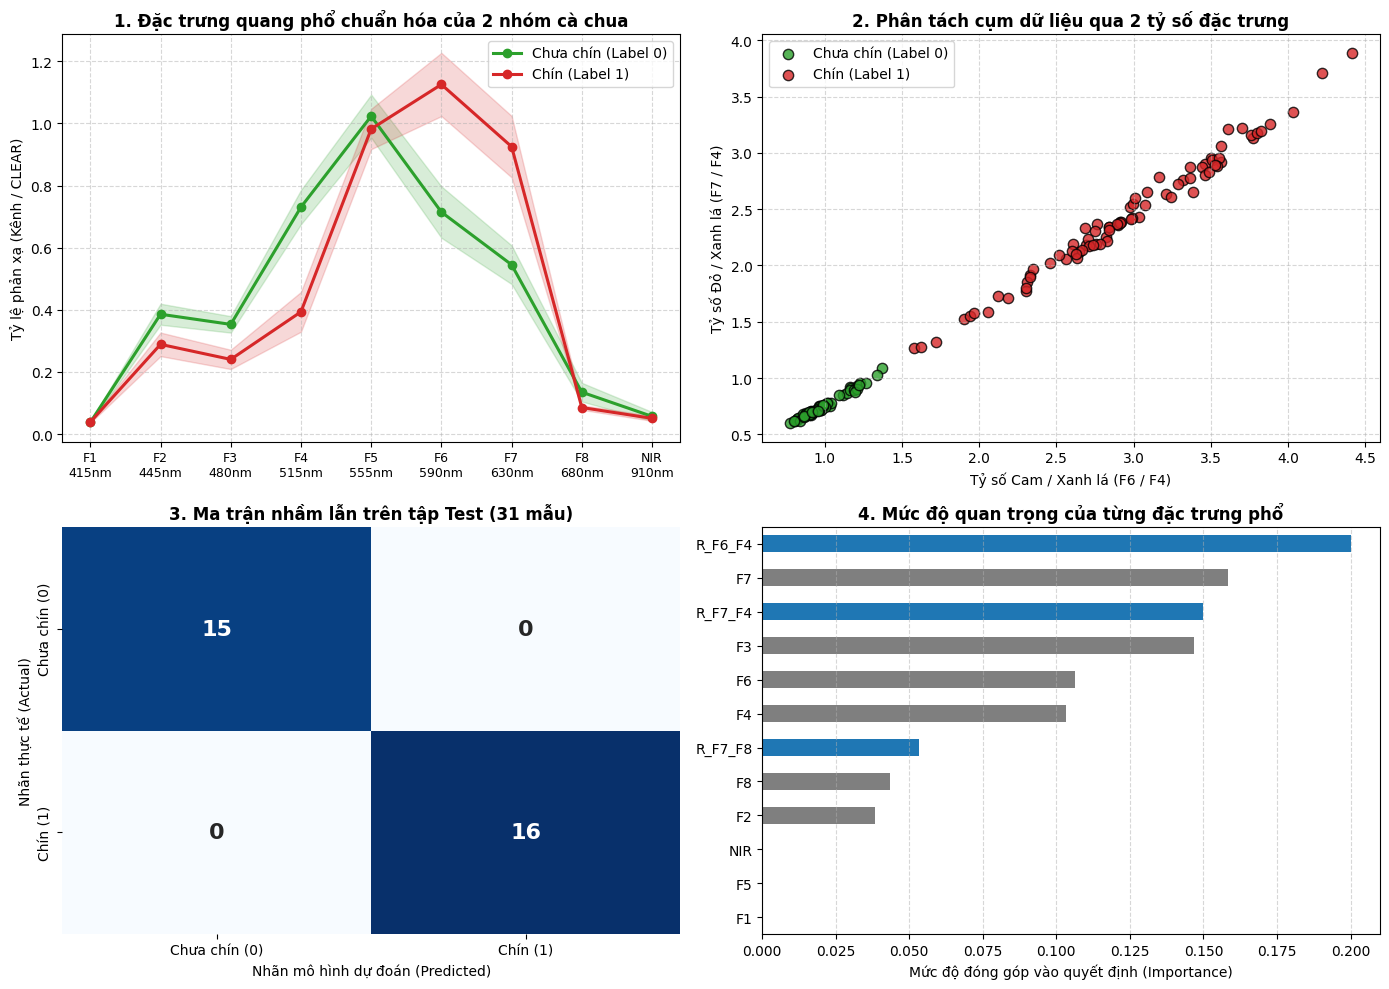

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Khởi tạo khung 4 biểu đồ (2 hàng x 2 cột)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- BIỂU ĐỒ 1: ĐƯỜNG CONG QUANG PHỔ CHUẨN HÓA ---
wavelengths = ['F1\n415nm', 'F2\n445nm', 'F3\n480nm', 'F4\n515nm',
               'F5\n555nm', 'F6\n590nm', 'F7\n630nm', 'F8\n680nm', 'NIR\n910nm']
x_idx = np.arange(len(wavelengths))

for lbl, color, name in [(0, '#2ca02c', 'Chưa chín (Label 0)'), (1, '#d62728', 'Chín (Label 1)')]:
    sub = X[y == lbl][spectral_cols]
    mean_v = sub.mean().values
    std_v = sub.std().values
    axes[0, 0].plot(x_idx, mean_v, marker='o', linewidth=2.2, color=color, label=name)
    axes[0, 0].fill_between(x_idx, mean_v - std_v, mean_v + std_v, color=color, alpha=0.18)

axes[0, 0].set_xticks(x_idx)
axes[0, 0].set_xticklabels(wavelengths, fontsize=9)
axes[0, 0].set_ylabel('Tỷ lệ phản xạ (Kênh / CLEAR)')
axes[0, 0].set_title('1. Đặc trưng quang phổ chuẩn hóa của 2 nhóm cà chua', fontweight='bold')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)
axes[0, 0].legend()

# --- BIỂU ĐỒ 2: PHÂN TÁCH CỤM QUA 2 TỶ SỐ ĐẶC TRƯNG ---
for lbl, color, name in [(0, '#2ca02c', 'Chưa chín (Label 0)'), (1, '#d62728', 'Chín (Label 1)')]:
    sub = X[y == lbl]
    axes[0, 1].scatter(sub['R_F6_F4'], sub['R_F7_F4'], c=color, alpha=0.8, edgecolors='k', s=55, label=name)

axes[0, 1].set_xlabel('Tỷ số Cam / Xanh lá (F6 / F4)')
axes[0, 1].set_ylabel('Tỷ số Đỏ / Xanh lá (F7 / F4)')
axes[0, 1].set_title('2. Phân tách cụm dữ liệu qua 2 tỷ số đặc trưng', fontweight='bold')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)
axes[0, 1].legend()

# --- BIỂU ĐỒ 3: MA TRẬN NHẦM LẪN (CONFUSION MATRIX) ---
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1, 0],
            annot_kws={'size': 16, 'weight': 'bold'},
            xticklabels=['Chưa chín (0)', 'Chín (1)'],
            yticklabels=['Chưa chín (0)', 'Chín (1)'])
axes[1, 0].set_xlabel('Nhãn mô hình dự đoán (Predicted)')
axes[1, 0].set_ylabel('Nhãn thực tế (Actual)')
axes[1, 0].set_title('3. Ma trận nhầm lẫn trên tập Test (31 mẫu)', fontweight='bold')

# --- BIỂU ĐỒ 4: MỨC ĐỘ QUAN TRỌNG CỦA CÁC ĐẶC TRƯNG ---
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)
colors_bar = ['#1f77b4' if idx.startswith('R_') else '#7f7f7f' for idx in importances.index]
importances.plot(kind='barh', ax=axes[1, 1], color=colors_bar)
axes[1, 1].set_xlabel('Mức độ đóng góp vào quyết định (Importance)')
axes[1, 1].set_title('4. Mức độ quan trọng của từng đặc trưng phổ', fontweight='bold')
axes[1, 1].grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('bieu_do_bao_cao.png', dpi=300) # Xuất file ảnh chất lượng cao
plt.show()